## 13. Sistemas lineares via autovalores

No Notebook 12 vimos que $\mathbf{y}=\mathbf{v}e^{\lambda t}$ é uma solução do sistema $\mathbf{y}'=\mathbf{A}\mathbf{y}$ sempre que $\lambda$ é um autovalor de $\mathbf{A}$ e $\mathbf{v}$ um autovetor associado. Neste notebook vamos usar essas soluções para montar a **solução geral** de sistemas lineares homogêneos com coeficientes constantes e resolver problemas de valor inicial.

Como a equação característica pode ter raízes reais distintas, complexas ou repetidas, há três casos a considerar — exatamente como para as EDOs lineares de 2ª ordem do Notebook 7, que, aliás, são um caso particular (Notebook 12, Exercício 2). Ao longo do notebook usaremos a função `residuo` do Notebook 10 para verificar soluções e a função `retrato_de_fase` do Notebook 11 para desenhá-las; ambas são repetidas na célula abaixo para o notebook ficar autocontido.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
sp.init_printing()

t = sp.symbols('t', real=True)

def residuo(A, y):
    '''Resíduo y' - A y, simplificado (é o vetor nulo se y for solução de y' = A y).'''
    return sp.simplify(y.diff(t) - A*y)

def retrato_de_fase(A, b=(0, 0), xlim=(-4, 4), ylim=(-3, 3), iniciais=(), T=20, ax=None):
    """Desenha o retrato de fase de y' = A y + b: linhas de fluxo, trajetórias que
    passam pelos pontos em `iniciais` (calculadas para t em [-T, T], parando quando
    saem da janela) e o ponto crítico."""
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    if ax is None:
        ax = plt.gca()
    Y1, Y2 = np.meshgrid(np.linspace(*xlim, 30), np.linspace(*ylim, 30))
    V1 = A[0,0]*Y1 + A[0,1]*Y2 + b[0]
    V2 = A[1,0]*Y1 + A[1,1]*Y2 + b[1]
    ax.streamplot(Y1, Y2, V1, V2, color='lightblue', density=1.2, linewidth=1)

    F = lambda t, y: A @ y + b
    # evento: interrompe a integração quando a trajetória se afasta bastante da janela
    cx, cy = np.mean(xlim), np.mean(ylim)
    lx, ly = xlim[1] - xlim[0], ylim[1] - ylim[0]
    fora = lambda t, y: max(abs(y[0] - cx)/lx, abs(y[1] - cy)/ly) - 1
    fora.terminal = True
    for y0 in iniciais:
        for t_final in (T, -T):                      # para a frente e para trás no tempo
            s = solve_ivp(F, (0, t_final), y0, max_step=0.02, events=fora)
            ax.plot(s.y[0], s.y[1], 'r-', lw=1.2)
        ax.plot(*y0, 'ko', ms=3)

    if np.linalg.det(A) != 0:
        eq = np.linalg.solve(A, -b)
        ax.plot(*eq, 'o', color='navy', ms=6)        # ponto crítico
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel('$y_1$'); ax.set_ylabel('$y_2$')
    return ax

### 13.1 A solução geral

Seja $\mathbf{A}$ uma matriz $n\times n$ de números reais. Pelo princípio da superposição (Seção 10.1), se $\mathbf{y}^{(1)},\dots,\mathbf{y}^{(n)}$ são soluções de $\mathbf{y}'=\mathbf{A}\mathbf{y}$, qualquer combinação linear

$$
\mathbf{y}=c_1\mathbf{y}^{(1)}+c_2\mathbf{y}^{(2)}+\dots+c_n\mathbf{y}^{(n)}
$$

também é solução. Se, além disso, as $n$ soluções forem **linearmente independentes**, essa combinação é a **solução geral**: qualquer solução do sistema pode ser escrita assim, para alguma escolha das constantes (Boyce e DiPrima, 2020, Seção 7.4). Um conjunto de $n$ soluções linearmente independentes é chamado **conjunto fundamental de soluções**.

Quando $\mathbf{A}$ tem $n$ autovetores linearmente independentes $\mathbf{v}_1,\dots,\mathbf{v}_n$, associados aos autovalores $\lambda_1,\dots,\lambda_n$ (não necessariamente distintos), as soluções $\mathbf{v}_ke^{\lambda_kt}$ formam um conjunto fundamental, e a solução geral é

$$
\mathbf{y}(t)=c_1\mathbf{v}_1e^{\lambda_1t}+c_2\mathbf{v}_2e^{\lambda_2t}+\dots+c_n\mathbf{v}_ne^{\lambda_nt}.
$$

Isso acontece, em particular, quando os $n$ autovalores são todos distintos (autovetores de autovalores distintos são sempre independentes) e quando $\mathbf{A}$ é simétrica. A independência pode ser conferida pelo determinante da matriz $\mathbf{V}=[\mathbf{v}_1\ \cdots\ \mathbf{v}_n]$, cujas colunas são os autovetores: eles são independentes se, e somente se, $\det\mathbf{V}\neq0$.

Restam dois cuidados, tratados nas Seções 13.3 e 13.4: quando os autovalores são **complexos**, as soluções $\mathbf{v}e^{\lambda t}$ são complexas, e queremos escrever a solução geral com funções reais; e quando um autovalor **repetido** não tem autovetores independentes suficientes (multiplicidade geométrica menor que a algébrica, Seção 12.4), faltam soluções da forma $\mathbf{v}e^{\lambda t}$.

### 13.2 Autovalores reais distintos

**Exemplo 13.1:** Encontre a solução geral do sistema
$$
\mathbf{y}'=\begin{bmatrix}3&-1\\4&-2\end{bmatrix}\mathbf{y}.
$$

*Solução:* a matriz é a do Exemplo 12.3, com autovalores $\lambda_1=-1$ e $\lambda_2=2$ e autovetores $\mathbf{v}_1=(1,4)$ e $\mathbf{v}_2=(1,1)$. Como os autovalores são distintos, a solução geral é

$$
\mathbf{y}(t)=c_1\begin{bmatrix}1\\4\end{bmatrix}e^{-t}+c_2\begin{bmatrix}1\\1\end{bmatrix}e^{2t}.
$$

Vamos conferir com o SymPy: a combinação tem resíduo nulo, os autovetores são independentes e o `sp.dsolve` dá a mesma família de soluções.

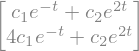

det V = -3


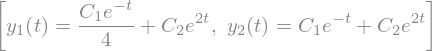

In [2]:
A = sp.Matrix([[3, -1], [4, -2]])
c1, c2 = sp.symbols('c_1 c_2')
v1, v2 = sp.Matrix([1, 4]), sp.Matrix([1, 1])
y = c1*v1*sp.exp(-t) + c2*v2*sp.exp(2*t)
display(y, residuo(A, y))
print('det V =', sp.Matrix.hstack(v1, v2).det())

y1, y2 = sp.Function('y1'), sp.Function('y2')
sp.dsolve([sp.Eq(y1(t).diff(t), 3*y1(t) - y2(t)),
           sp.Eq(y2(t).diff(t), 4*y1(t) - 2*y2(t))], [y1(t), y2(t)])

O `sp.dsolve` escreve as constantes de outra forma, mas os expoentes e as direções $(1,4)$ e $(1,1)$ são os mesmos.

A solução geral explica o retrato de fase. As soluções com $c_2=0$ ficam sobre a reta de $\mathbf{v}_1$ e se aproximam da origem ($e^{-t}\to0$); as com $c_1=0$ ficam sobre a reta de $\mathbf{v}_2$ e se afastam dela ($e^{2t}$ cresce). Todas as outras combinam as duas coisas: para $t$ grande o termo $c_2\mathbf{v}_2e^{2t}$ domina, e a trajetória se afasta acompanhando a direção de $\mathbf{v}_2$. É um **ponto de sela** — o tipo do Exemplo 11.3, agora com as retas especiais inclinadas:

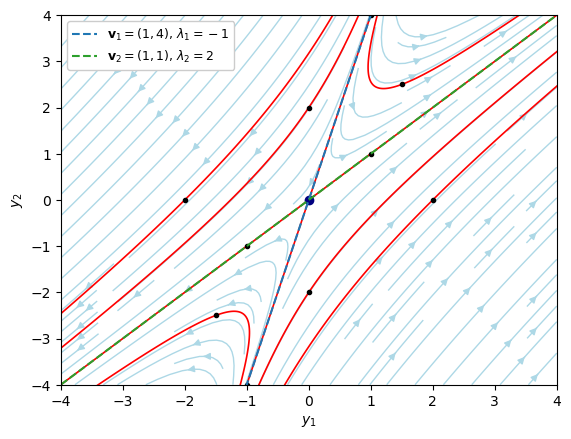

In [3]:
iniciais = [(-1, -4), (1, 4), (1, 1), (-1, -1), (2, 0), (-2, 0), (0, 2), (0, -2),
            (1.5, 2.5), (-1.5, -2.5)]
ax = retrato_de_fase(A, xlim=(-4, 4), ylim=(-4, 4), iniciais=iniciais)
s = np.array([-5, 5])
ax.plot(s*1, s*4, '--', color='tab:blue', lw=1.5, label=r'$\mathbf{v}_1=(1,4)$, $\lambda_1=-1$')
ax.plot(s*1, s*1, '--', color='tab:green', lw=1.5, label=r'$\mathbf{v}_2=(1,1)$, $\lambda_2=2$')
ax.legend(loc='upper left', fontsize=9, framealpha=1)
plt.show()

**Exemplo 13.2:** (Adaptado de Brannan e Boyce, 2008) Encontre a solução geral de

$$
\mathbf{y}'=\begin{bmatrix}-\frac45&-\frac15&\frac45\\[1mm]-\frac15&-\frac45&-\frac45\\[1mm]\frac25&-\frac25&\frac35\end{bmatrix}\mathbf{y}
$$

e desenhe algumas trajetórias no espaço $y_1y_2y_3$.

*Solução:* com `sp.Rational`, para trabalhar com frações exatas:

In [4]:
R = sp.Rational
A = sp.Matrix([[-R(4, 5), -R(1, 5),  R(4, 5)],
               [-R(1, 5), -R(4, 5), -R(4, 5)],
               [ R(2, 5), -R(2, 5),  R(3, 5)]])
lamb = sp.symbols('lambda')
display(sp.Eq(sp.factor((A - lamb*sp.eye(3)).det()), 0))
for val, m, vetores in A.eigenvects():
    print(f'λ = {val}:  mult. algébrica = {m},  autovetores:', [list(w) for w in vetores])

λ = -1:  mult. algébrica = 2,  autovetores: [[1, 1, 0], [-4, 0, 1]]
λ = 1:  mult. algébrica = 1,  autovetores: [[1/2, -1/2, 1]]


O autovalor $\lambda_1=-1$ é duplo, mas — como no Exemplo 12.4 — tem **dois** autovetores independentes. O SymPy devolve $(1,1,0)$ e $(-4,0,1)$; qualquer par de combinações independentes deles serve, e vamos usar $\mathbf{v}_1=(2,2,0)$ e $\mathbf{v}_2=(-2,2,1)$, como no livro. O autovalor $\lambda_2=1$ tem autovetor $\mathbf{v}_3=(1,-1,2)$. Os três vetores são independentes, então a solução geral é

$$
\mathbf{y}(t)=c_1e^{-t}\begin{bmatrix}2\\2\\0\end{bmatrix}+c_2e^{-t}\begin{bmatrix}-2\\2\\1\end{bmatrix}+c_3e^{t}\begin{bmatrix}1\\-1\\2\end{bmatrix}.
$$

In [5]:
c1, c2, c3 = sp.symbols('c_1 c_2 c_3')
v1, v2, v3 = sp.Matrix([2, 2, 0]), sp.Matrix([-2, 2, 1]), sp.Matrix([1, -1, 2])
print('A v1 = -v1?', A*v1 == -v1, '   A v2 = -v2?', A*v2 == -v2, '   A v3 = v3?', A*v3 == v3)
print('det V =', sp.Matrix.hstack(v1, v2, v3).det())
y = c1*v1*sp.exp(-t) + c2*v2*sp.exp(-t) + c3*v3*sp.exp(t)
display(residuo(A, y))

A v1 = -v1? True    A v2 = -v2? True    A v3 = v3? True
det V = 20


No gráfico abaixo desenhamos as trajetórias de várias soluções (em vermelho, para $-0{,}7\le t\le1{,}2$, com um ponto preto no instante final), o **plano** gerado por $\mathbf{v}_1$ e $\mathbf{v}_2$ (em cinza) e a **reta** de $\mathbf{v}_3$ (em preto). Os termos com $e^{-t}$ decaem e o termo com $e^{t}$ cresce: as trajetórias começam perto do plano, aproximam-se da origem e depois se afastam dela acompanhando a reta de $\mathbf{v}_3$. As soluções com $c_3=0$ ficam sobre o plano e tendem à origem.

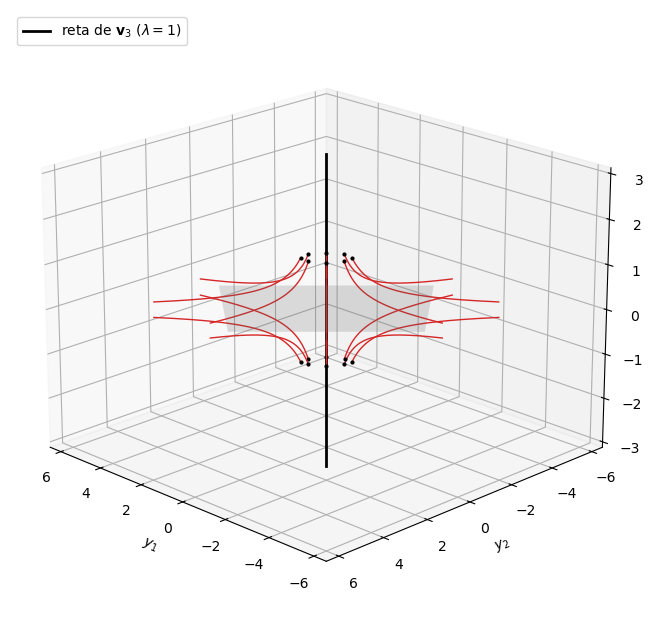

In [6]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d')
v1, v2, v3 = np.array([2, 2, 0]), np.array([-2, 2, 1]), np.array([1, -1, 2])

# plano gerado por v1 e v2 (soluções com c3 = 0) e reta de v3
a, b = np.meshgrid(np.linspace(-1.2, 1.2, 2), np.linspace(-1.5, 1.5, 2))
P = a[..., None]*v1 + b[..., None]*v2
ax.plot_surface(P[..., 0], P[..., 1], P[..., 2], color='gray', alpha=0.2)
r = np.array([-1.5, 1.5])
ax.plot(r*v3[0], r*v3[1], r*v3[2], 'k-', lw=2, label=r'reta de $\mathbf{v}_3$ ($\lambda=1$)')

ts = np.linspace(-0.7, 1.2, 200)
for (a, b) in [(1, 0), (-1, 0), (0, 1), (0, -1), (0.7, 0.7), (-0.7, -0.7), (0.7, -0.7), (-0.7, 0.7)]:
    for c in [-0.15, 0.15]:
        Y = np.outer(a*v1 + b*v2, np.exp(-ts)) + c*np.outer(v3, np.exp(ts))
        ax.plot(*Y, color='tab:red', lw=1)
        ax.plot(*Y[:, -1], 'k.', ms=4)                     # ponto final (t = 1,2)
ax.set_xlabel('$y_1$'); ax.set_ylabel('$y_2$'); ax.set_zlabel('$y_3$')
ax.legend(loc='upper left')
ax.view_init(20, 135)
plt.show()

#### Atividade 13.1

(Brannan e Boyce, 2008) Encontre a solução geral de
$$
\mathbf{y}'=\begin{bmatrix}-1&-1&1&1\\-3&-4&-3&6\\0&-3&-2&3\\-3&-5&-3&7\end{bmatrix}\mathbf{y}
$$
e verifique, com a função `residuo`, que ela é solução do sistema.

### 13.3 Autovalores complexos

Se $\lambda=\alpha+i\beta$ (com $\beta\neq0$) é um autovalor de $\mathbf{A}$, com autovetor $\mathbf{v}=\mathbf{a}+i\mathbf{b}$ ($\mathbf{a}$ e $\mathbf{b}$ vetores reais), então $\mathbf{v}e^{\lambda t}$ é uma solução **complexa**. Usando a fórmula de Euler, $e^{(\alpha+i\beta)t}=e^{\alpha t}(\cos\beta t+i\,\operatorname{sen}\beta t)$, ela se separa em parte real e parte imaginária:

$$
\mathbf{v}e^{\lambda t}=\underbrace{e^{\alpha t}\left(\mathbf{a}\cos\beta t-\mathbf{b}\operatorname{sen}\beta t\right)}_{\mathbf{u}(t)}
+i\,\underbrace{e^{\alpha t}\left(\mathbf{a}\operatorname{sen}\beta t+\mathbf{b}\cos\beta t\right)}_{\mathbf{w}(t)}.
$$

Como $\mathbf{A}$ é real, $\mathbf{u}$ e $\mathbf{w}$ são, cada uma, soluções **reais** do sistema, e são linearmente independentes. O autovalor conjugado $\bar\lambda$ não traz nada de novo (as partes real e imaginária de $\bar{\mathbf{v}}e^{\bar\lambda t}$ são $\mathbf{u}$ e $-\mathbf{w}$). Assim, para um sistema $2\times2$ com autovalores $\alpha\pm i\beta$, a solução geral em funções reais é

$$
\mathbf{y}(t)=c_1\mathbf{u}(t)+c_2\mathbf{w}(t).
$$

O fator $e^{\alpha t}$ controla a distância até a origem (decai se $\alpha<0$, cresce se $\alpha>0$) e os senos e cossenos, de frequência $\beta$, fazem as trajetórias girar — é a origem dos pontos espirais e centros do Notebook 11. O mesmo raciocínio já foi usado para as EDOs de 2ª ordem com raízes complexas no Notebook 7.

**Exemplo 13.3:** (Boyce e DiPrima, 2020) Encontre um conjunto fundamental de soluções reais para o sistema

$$
\mathbf{y}'=\begin{bmatrix}-\frac12&1\\-1&-\frac12\end{bmatrix}\mathbf{y},
$$

desenhe o retrato de fase e faça os gráficos das componentes de uma solução típica.

*Solução:* a matriz é a do Exemplo 12.6, com autovalores $-\frac12\pm i$. Tomamos o autovetor de $\lambda=-\frac12+i$ e separamos as partes real e imaginária de $\mathbf{v}e^{\lambda t}$:

λ = -1/2 + I    v = [1, I]


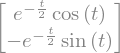

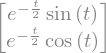

In [7]:
A = sp.Matrix([[-sp.Rational(1, 2), 1], [-1, -sp.Rational(1, 2)]])
lam, m, (v,) = [ev for ev in A.eigenvects() if sp.im(ev[0]) > 0][0]
v = sp.I*v                                     # múltiplo mais simples do autovetor: (1, i)
print('λ =', lam, '   v =', list(v))
z = sp.expand_complex(v*sp.exp(lam*t))
u = z.applyfunc(sp.re)
w = z.applyfunc(sp.im)
display(u, w, residuo(A, u), residuo(A, w))

Com $\mathbf{v}=(1,i)$, ou seja, $\mathbf{a}=(1,0)$ e $\mathbf{b}=(0,1)$, obtemos

$$
\mathbf{u}(t)=e^{-t/2}\begin{bmatrix}\cos t\\-\operatorname{sen}t\end{bmatrix},\qquad
\mathbf{w}(t)=e^{-t/2}\begin{bmatrix}\operatorname{sen}t\\\cos t\end{bmatrix},
$$

ambas com resíduo nulo, e a solução geral real é $\mathbf{y}=c_1\mathbf{u}+c_2\mathbf{w}$. (O autovetor dado pelo SymPy, $(-i,1)$, é $-i$ vezes $(1,i)$; multiplicar o autovetor por uma constante complexa troca o par $\mathbf{u},\mathbf{w}$ por outro par de soluções reais, que gera a mesma família.)

As trajetórias espiralam para a origem no sentido horário, e as componentes oscilam com frequência $\beta=1$ (período $2\pi$) e amplitude decaindo como $e^{-t/2}$:

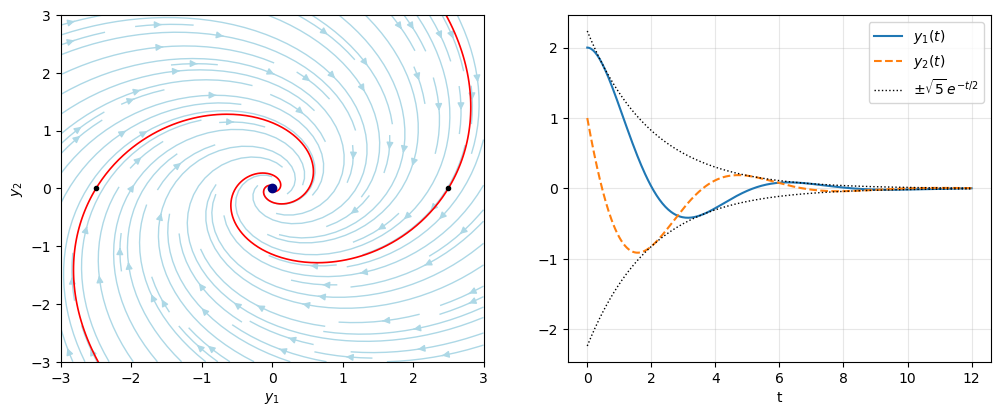

In [8]:
c1, c2 = sp.symbols('c_1 c_2')
y = c1*u + c2*w
y_num = sp.lambdify((t, c1, c2), list(y))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
retrato_de_fase(A, xlim=(-3, 3), ylim=(-3, 3), iniciais=[(2.5, 0), (-2.5, 0)], T=12, ax=ax1)
ts = np.linspace(0, 12, 400)
Y1, Y2 = y_num(ts, 2, 1)                       # a solução com c1 = 2, c2 = 1, isto é, y(0) = (2, 1)
ax2.plot(ts, Y1, label='$y_1(t)$')
ax2.plot(ts, Y2, '--', label='$y_2(t)$')
ax2.plot(ts, np.sqrt(5)*np.exp(-ts/2), 'k:', lw=1, label=r'$\pm\sqrt{5}\,e^{-t/2}$')
ax2.plot(ts, -np.sqrt(5)*np.exp(-ts/2), 'k:', lw=1)
ax2.set_xlabel('t'); ax2.legend(); ax2.grid(alpha=0.3)
plt.show()

#### Atividade 13.2

Encontre a solução geral, em termos de funções reais, do sistema $\mathbf{y}'=\begin{bmatrix}0&-2\\1&2\end{bmatrix}\mathbf{y}$ (a matriz da Atividade 12.3). Verifique as duas soluções com a função `residuo`, desenhe o retrato de fase e descreva o comportamento das soluções quando $t\to\infty$.

### 13.4 Autovalores repetidos

Se um autovalor $\lambda$ de multiplicidade algébrica 2 tem dois autovetores independentes (como no Exemplo 13.2), nada muda: cada um deles dá uma solução $\mathbf{v}e^{\lambda t}$. O caso novo é quando há só **um** autovetor independente $\mathbf{v}$ (multiplicidade geométrica 1, como no Exemplo 12.5): temos a solução $\mathbf{y}^{(1)}=\mathbf{v}e^{\lambda t}$ e precisamos de uma segunda.

Inspirados nas EDOs de 2ª ordem com raiz dupla (Notebook 7), em que a segunda solução é $te^{rt}$, tentamos $\mathbf{y}=\mathbf{v}te^{\lambda t}+\mathbf{w}e^{\lambda t}$. Substituindo em $\mathbf{y}'=\mathbf{A}\mathbf{y}$:

$$
\mathbf{v}e^{\lambda t}+\lambda\mathbf{v}te^{\lambda t}+\lambda\mathbf{w}e^{\lambda t}=\mathbf{A}\mathbf{v}te^{\lambda t}+\mathbf{A}\mathbf{w}e^{\lambda t}.
$$

Igualando os termos em $te^{\lambda t}$, obtemos $\mathbf{A}\mathbf{v}=\lambda\mathbf{v}$ (verdade, pois $\mathbf{v}$ é autovetor); igualando os termos em $e^{\lambda t}$, obtemos

$$
(\mathbf{A}-\lambda\mathbf{I})\mathbf{w}=\mathbf{v}.
$$

Um vetor $\mathbf{w}$ que satisfaz essa equação é chamado **autovetor generalizado**. A solução geral é então

$$
\mathbf{y}(t)=c_1\mathbf{v}e^{\lambda t}+c_2\left(\mathbf{v}t+\mathbf{w}\right)e^{\lambda t}.
$$

(Note que a tentativa mais ingênua, $\mathbf{v}te^{\lambda t}$ sozinha, não funciona: sem o termo $\mathbf{w}e^{\lambda t}$, sobraria $\mathbf{v}e^{\lambda t}=\mathbf{0}$.)

**Exemplo 13.4:** (Boyce e DiPrima, 2020) Encontre um conjunto fundamental de soluções para

$$
\mathbf{y}'=\begin{bmatrix}1&-1\\1&3\end{bmatrix}\mathbf{y}
$$

e desenhe o retrato de fase do sistema.

*Solução:* pelo Exemplo 12.5, $\lambda=2$ é autovalor duplo com um único autovetor independente; tomamos $\mathbf{v}=(1,-1)$. Resolvemos $(\mathbf{A}-2\mathbf{I})\mathbf{w}=\mathbf{v}$:

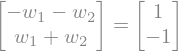

In [9]:
A = sp.Matrix([[1, -1], [1, 3]])
v = sp.Matrix([1, -1])
w1, w2 = sp.symbols('w_1 w_2')
display(sp.Eq((A - 2*sp.eye(2))*sp.Matrix([w1, w2]), v))
sp.solve((A - 2*sp.eye(2))*sp.Matrix([w1, w2]) - v, [w1, w2])

As duas equações se reduzem a $-w_1-w_2=1$: há infinitas soluções (podemos somar a $\mathbf{w}$ qualquer múltiplo de $\mathbf{v}$). Escolhendo $w_1=0$, temos $\mathbf{w}=(0,-1)$, e a solução geral é

$$
\mathbf{y}(t)=c_1\begin{bmatrix}1\\-1\end{bmatrix}e^{2t}+c_2\left(\begin{bmatrix}1\\-1\end{bmatrix}t+\begin{bmatrix}0\\-1\end{bmatrix}\right)e^{2t}.
$$

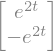

In [10]:
w = sp.Matrix([0, -1])
c1, c2 = sp.symbols('c_1 c_2')
y = c1*v*sp.exp(2*t) + c2*(v*t + w)*sp.exp(2*t)
display(residuo(A, y))
display(residuo(A, v*t*sp.exp(2*t)))           # a tentativa ingênua: não é solução

O resíduo da solução geral é nulo, e o da tentativa ingênua $\mathbf{v}te^{2t}$ é $-\mathbf{v}e^{2t}\neq\mathbf{0}$, como previsto.

No retrato de fase, todas as trajetórias se afastam da origem ($e^{2t}$ cresce). Perto da origem elas saem tangentes à reta do único autovetor, $y_2=-y_1$; longe dela, o termo $c_2\mathbf{v}te^{2t}$ domina e elas voltam a ficar paralelas a essa mesma reta. O resultado é uma figura em forma de "S", que não tem as duas retas especiais de um nó com dois autovetores — é um **nó impróprio degenerado** (Notebook 14):

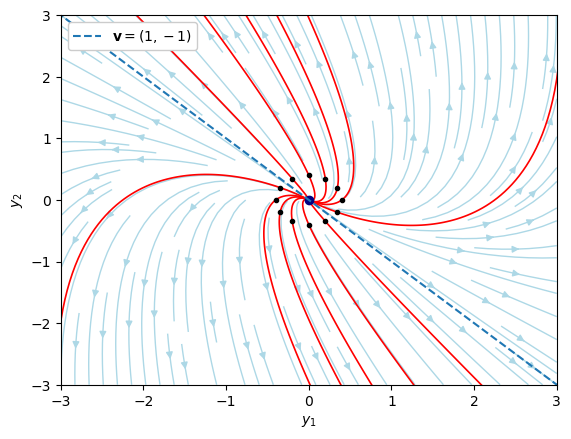

In [11]:
ang = np.linspace(0, 2*np.pi, 12, endpoint=False)
iniciais = [(0.4*np.cos(a), 0.4*np.sin(a)) for a in ang]
ax = retrato_de_fase(A, xlim=(-3, 3), ylim=(-3, 3), iniciais=iniciais, T=5)
s = np.array([-5, 5])
ax.plot(s, -s, '--', color='tab:blue', lw=1.5, label=r'$\mathbf{v}=(1,-1)$')
ax.legend(loc='upper left', framealpha=1)
plt.show()

#### Atividade 13.3

Mostre que a matriz $\mathbf{A}=\begin{bmatrix}-1&1\\-4&3\end{bmatrix}$ tem um autovalor duplo com um único autovetor independente, encontre um autovetor generalizado e escreva a solução geral de $\mathbf{y}'=\mathbf{A}\mathbf{y}$. Confira com a função `residuo` e com o `sp.dsolve`.

### 13.5 Problemas de valor inicial

Dada a solução geral, a condição inicial $\mathbf{y}(0)=\mathbf{y}_0$ determina as constantes. No caso em que há $n$ autovetores independentes,

$$
\mathbf{y}(0)=c_1\mathbf{v}_1+\dots+c_n\mathbf{v}_n=\mathbf{V}\mathbf{c}=\mathbf{y}_0,
$$

ou seja, as constantes são a solução do sistema linear $\mathbf{V}\mathbf{c}=\mathbf{y}_0$, cuja matriz tem os autovetores como colunas — o mesmo formato da matriz `V` devolvida pelo `np.linalg.eig` (Seção 12.6).

**Exemplo 13.5:** Resolva o problema de valor inicial $\mathbf{y}'=\begin{bmatrix}3&-1\\4&-2\end{bmatrix}\mathbf{y}$, $\mathbf{y}(0)=\begin{bmatrix}2\\5\end{bmatrix}$ (o sistema do Exemplo 13.1).

*Solução:* primeiro com o SymPy, de forma exata:

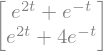

In [12]:
A = sp.Matrix([[3, -1], [4, -2]])
V = sp.Matrix([[1, 1], [4, 1]])                # colunas: v1 = (1, 4) e v2 = (1, 1)
c = V.solve(sp.Matrix([2, 5]))
display(c)
y = c[0]*V[:, 0]*sp.exp(-t) + c[1]*V[:, 1]*sp.exp(2*t)
display(y, residuo(A, y), y.subs(t, 0))

O sistema $c_1+c_2=2$, $4c_1+c_2=5$ dá $c_1=c_2=1$, e a solução é $\mathbf{y}(t)=(1,4)^Te^{-t}+(1,1)^Te^{2t}$.

O mesmo cálculo pode ser feito numericamente, para qualquer matriz que tenha $n$ autovetores independentes: o `np.linalg.eig` dá os autovalores $\lambda_k$ e a matriz $\mathbf{V}$, o `np.linalg.solve` dá as constantes, e a solução em cada instante é $\mathbf{y}(t)=\sum_kc_k\mathbf{v}_ke^{\lambda_kt}$. A função abaixo faz isso e funciona também com autovalores complexos: nesse caso os $c_k$ e as parcelas são complexos, mas a soma é real (a menos de erros de arredondamento), e tomamos a sua parte real.

In [13]:
def solucao_pvi(A, y0, ts):
    '''Solução de y' = A y, y(0) = y0, nos instantes ts, pelos autovalores e autovetores de A
    (supõe que A tem n autovetores linearmente independentes).'''
    lam, V = np.linalg.eig(np.array(A, dtype=float))
    c = np.linalg.solve(V, np.array(y0, dtype=float))
    Y = V @ (c[:, None]*np.exp(np.outer(lam, ts)))   # coluna j: soma de c_k v_k e^{λ_k t_j}
    return np.real(Y)

ts = np.linspace(0, 1, 5)
print('autovalores:', np.linalg.eigvals(np.array(A, dtype=float)))
print('y(t) pelos autovetores:\n', solucao_pvi(A, [2, 5], ts))
print('y(t) exata:\n', np.array([[float(e.subs(t, tk)) for tk in ts] for e in y]))

autovalores: [ 2. -1.]
y(t) pelos autovetores:
 [[2.         2.42752205 3.32481249 4.95405562 7.75693554]
 [5.         4.7639244  5.14440447 6.37115528 8.86057386]]
y(t) exata:
 [[2.         2.42752205 3.32481249 4.95405562 7.75693554]
 [5.         4.7639244  5.14440447 6.37115528 8.86057386]]


Os valores coincidem com a solução exata. Para o sistema do Exemplo 13.3, com autovalores complexos, comparamos com o `solve_ivp`:

In [14]:
A3 = np.array([[-0.5, 1], [-1, -0.5]])
ts = np.linspace(0, 10, 6)
s = solve_ivp(lambda t, y: A3 @ y, (0, 10), [2, 1], t_eval=ts, rtol=1e-10, atol=1e-12)
Y = solucao_pvi(A3, [2, 1], ts)
print('pelos autovetores:\n', Y)
print('diferença máxima para o solve_ivp:', np.max(np.abs(Y - s.y)))

pelos autovetores:
 [[ 2.00000000e+00  2.83280979e-02 -2.79344169e-01  8.16968489e-02
   1.27908762e-02 -1.49728244e-02]
 [ 1.00000000e+00 -8.22115524e-01  1.16383116e-01  7.56266207e-02
  -3.89063828e-02  1.67755133e-03]]
diferença máxima para o solve_ivp: 2.497901885334386e-11


Esse procedimento **não** serve quando a matriz não tem $n$ autovetores independentes, como a do Exemplo 13.4: a matriz $\mathbf{V}$ do NumPy fica (quase) singular — as duas colunas são praticamente paralelas, como vimos na Seção 12.6 — e o sistema $\mathbf{V}\mathbf{c}=\mathbf{y}_0$ fica mal condicionado. O **número de condição** de $\mathbf{V}$ mede isso: quanto maior, mais os erros de arredondamento são amplificados.

In [15]:
for nome, M in [('Exemplo 13.1', [[3, -1], [4, -2]]), ('Exemplo 13.4', [[1, -1], [1, 3]])]:
    lam, V = np.linalg.eig(np.array(M, dtype=float))
    print(f'{nome}:  autovalores = {lam},  número de condição de V = {np.linalg.cond(V):.2e}')

Exemplo 13.1:  autovalores = [ 2. -1.],  número de condição de V = 3.61e+00
Exemplo 13.4:  autovalores = [2.00000002 1.99999998],  número de condição de V = 9.49e+07


Com número de condição da ordem de $10^8$, perdem-se cerca de 8 dos 16 algarismos significativos do ponto flutuante. Nesse caso, usamos a solução com o autovetor generalizado da Seção 13.4 (ou simplesmente o `solve_ivp`).

#### Atividade 13.4

Resolva o problema de valor inicial do sistema do Exemplo 13.2 com $\mathbf{y}(0)=(1,1,1)$: encontre as constantes $c_1,c_2,c_3$ de forma exata (SymPy) e calcule $\mathbf{y}(1)$. Confira o resultado com a função `solucao_pvi` e com o `solve_ivp`.

### 13.6 Exercícios

**1.** (Boyce e DiPrima, 2020) Em cada um dos sistemas abaixo, os autovalores são repetidos. Encontre a solução geral, desenhe o retrato de fase e descreva o comportamento das soluções quando $t\to\infty$.

a) $\mathbf{y}'=\begin{bmatrix}3&-4\\1&-1\end{bmatrix}\mathbf{y}$

b) $\mathbf{y}'=\begin{bmatrix}4&-2\\8&-4\end{bmatrix}\mathbf{y}$ (aqui o autovalor duplo é $\lambda=0$: o que isso significa para as soluções?)

**2.** (Boyce e DiPrima, 2020) Expresse a solução geral de cada sistema em termos de funções reais e descreva o comportamento das soluções quando $t\to\infty$.

a) $\mathbf{y}'=\begin{bmatrix}-1&-4\\1&-1\end{bmatrix}\mathbf{y}$

b) $\mathbf{y}'=\begin{bmatrix}2&-5\\1&-2\end{bmatrix}\mathbf{y}$ (compare com o Exercício 1(c) do Notebook 10)

c) $\mathbf{y}'=\begin{bmatrix}1&-1\\5&-3\end{bmatrix}\mathbf{y}$

d) $\mathbf{y}'=\begin{bmatrix}1&2\\-5&-1\end{bmatrix}\mathbf{y}$

**3.** (Boyce e DiPrima, 2020) Expresse a solução geral de cada sistema em termos de funções reais.

a) $\mathbf{y}'=\begin{bmatrix}1&0&0\\2&1&-2\\3&2&1\end{bmatrix}\mathbf{y}$ (a matriz do Exercício 1(d) do Notebook 12)

b) $\mathbf{y}'=\begin{bmatrix}-3&0&2\\1&-1&0\\-2&-1&0\end{bmatrix}\mathbf{y}$

c) $\mathbf{y}'=\begin{bmatrix}0&1&1\\1&0&1\\1&1&0\end{bmatrix}\mathbf{y}$ (use os autovalores e autovetores do Exemplo 12.4)

d) $\mathbf{y}'=\begin{bmatrix}1&1&1\\2&1&-1\\0&-1&1\end{bmatrix}\mathbf{y}$ (há um autovalor duplo com um único autovetor: use um autovetor generalizado)

**4.** (Boyce e DiPrima, 2020) Encontre a solução de cada problema de valor inicial, confira com o `solve_ivp` e descreva o comportamento da solução quando $t\to\infty$.

a) $\mathbf{y}'=\begin{bmatrix}1&-5\\1&-3\end{bmatrix}\mathbf{y}$, $\quad\mathbf{y}(0)=\begin{bmatrix}1\\1\end{bmatrix}$

b) $\mathbf{y}'=\begin{bmatrix}-3&2\\-1&-1\end{bmatrix}\mathbf{y}$, $\quad\mathbf{y}(0)=\begin{bmatrix}1\\-2\end{bmatrix}$

**Referências**

BOYCE, William E.; DIPRIMA, Richard C. Equações Diferenciais Elementares e Problemas de Valores de Contorno. Grupo GEN, 2020. E-book. ISBN 9788521637134. Disponível em: https://integrada.minhabiblioteca.com.br/#/books/9788521637134/.

BRANNAN, James R.; BOYCE, William E. Equações Diferenciais: uma Introdução a Métodos Modernos e suas Aplicações. São Paulo: Grupo GEN, 2008. E-book. ISBN 978-85-216-2337-3. Disponível em: https://integrada.minhabiblioteca.com.br/#/books/978-85-216-2337-3/.